# TP5 — CNN 1D sur séries temporelles

**Cours :** Réseaux de neurones convolutifs (CNN) — 30 h — Master 1 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 1 h 30  ·  **Barème :** 10 points

---

## Objectifs

- Transposer les principes de convolution à un signal 1D.
- Construire un détecteur de battements sur un ECG.
- Mesurer l'effet de différents noyaux 1D.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter les cellules **dans l'ordre** (`Shift + Entrée`).
- Les cellules marquées **« À vous »** sont à compléter : ce sont elles qui sont évaluées.
- Toutes les figures s'affichent dans le notebook ; si ce n'est pas le cas, vérifier que la
  première cellule a bien été exécutée.
- Reproductibilité : les graines aléatoires sont fixées. Deux exécutions donnent le même résultat.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(4112)

## 1. Un CNN ne se limite pas aux images

Un signal 1D — une mesure qui évolue dans le temps — se traite avec exactement les mêmes
principes : un noyau qui balaye, une activation, un pooling. On travaille ici sur un signal
de type **électrocardiogramme** synthétique.

duree : 10.0 s   |   points : 1200   |   frequence simulee : 72 bpm


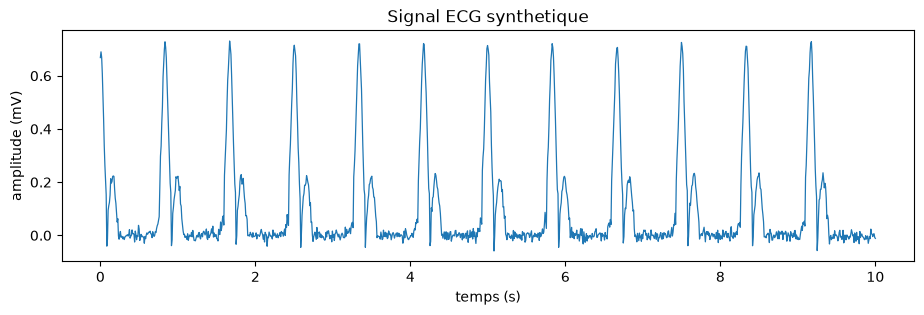

In [2]:
def ecg(n=1200, bpm=72, seed=4112):
    rng = np.random.default_rng(seed)
    t = np.linspace(0, 10, n)
    sig = np.zeros(n)
    for k in range(int(10 * bpm / 60)):
        c = k * 60 / bpm
        idx = np.argmin(np.abs(t - c))
        for dt, amp in [(-.05, .08), (0, -0.12), (0.012, 1.0), (0.03, -0.22), (0.16, 0.22)]:
            j = idx + int(dt * n / 10)
            if 0 <= j < n:
                w = max(2, int(.008 * n))
                lo, hi = max(0, j - w), j + w
                sig[lo:hi] += amp * np.exp(-((np.arange(lo, hi) - j) ** 2) / (2 * (.004 * n) ** 2))
    return t, sig + rng.normal(0, .012, n)

t, s = ecg()
print("duree :", t[-1], "s   |   points :", len(s), "  |   frequence simulee : 72 bpm")

plt.figure(figsize=(11, 3))
plt.plot(t, s, lw=.9)
plt.xlabel("temps (s)"); plt.ylabel("amplitude (mV)")
plt.title("Signal ECG synthetique")
plt.show()

## 2. Un noyau 1D

Un noyau 1D est un simple vecteur. Appliqué par balayage, il produit un nouveau signal.
Voici quatre noyaux aux rôles bien distincts.

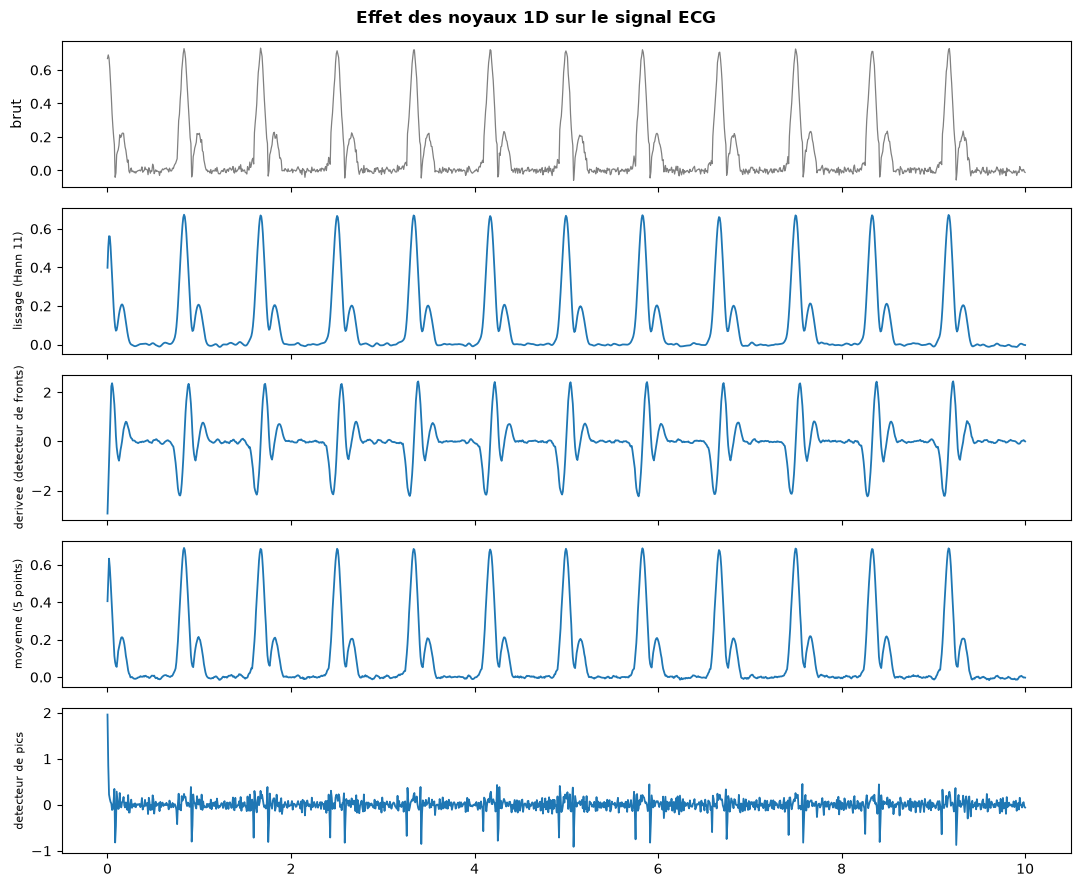

In [3]:
noyaux1d = {
    "lissage (Hann 11)":   np.hanning(11) / np.hanning(11).sum(),
    "derivee (detecteur de fronts)": np.array([-1, -1, -1, -1, -1, 0, 1, 1, 1, 1, 1], float),
    "moyenne (5 points)":  np.ones(5) / 5,
    "detecteur de pics":   np.array([-1, -2, 6, -2, -1], float),
}
fig, axes = plt.subplots(len(noyaux1d) + 1, 1, figsize=(11, 9), sharex=True)
axes[0].plot(t, s, color="grey", lw=.9); axes[0].set_ylabel("brut")
for ax, (nom, k) in zip(axes[1:], noyaux1d.items()):
    ax.plot(t, np.convolve(s, k, mode="same"), lw=1.3)
    ax.set_ylabel(nom, fontsize=8)
plt.suptitle("Effet des noyaux 1D sur le signal ECG", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Détecter les battements

Un détecteur de pics bien calibré, suivi d'un seuil, localise les complexes QRS.
C'est exactement ce que fait une couche convolutive apprise : elle découvre *seule*
le noyau qui fait ressortir le motif.

seuil      : 0.2143
battements : 11 detectes  (attendu ≈ 12 en 10 s a 72 bpm)


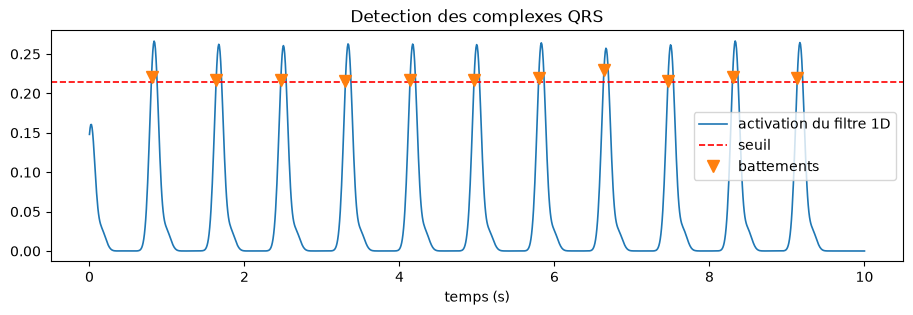

In [4]:
noyau = np.exp(-np.linspace(-1, 1, 41) ** 2 * 6)
noyau /= noyau.sum()
activation = np.convolve(np.maximum(s, 0) ** 2, noyau, mode="same")
seuil = activation.mean() + 2.2 * activation.std()
pics = (activation > seuil) & (np.roll(activation, 1) <= seuil)

print("seuil      :", round(float(seuil), 4))
print("battements :", int(pics.sum()), "detectes  (attendu ≈ 12 en 10 s a 72 bpm)")

plt.figure(figsize=(11, 3))
plt.plot(t, activation, lw=1.2, label="activation du filtre 1D")
plt.axhline(seuil, color="red", ls="--", lw=1.2, label="seuil")
plt.plot(t[pics], activation[pics], "v", ms=8, label="battements")
plt.legend(); plt.xlabel("temps (s)")
plt.title("Detection des complexes QRS")
plt.show()

## 4. À vous

**Question 1.** Un noyau 1D de longueur 21 appliqué à un signal de 600 points : combien de
points compte la sortie en mode `valid` ?

**Question 2.** Remplacez le noyau de détection par une simple moyenne mobile de 41 points.
Les pics sont-ils encore détectables ?

**Question 3.** Quelle est la différence essentielle entre un noyau 1D et un noyau 2D,
du point de vue du nombre de paramètres pour une même longueur $K$ ?

In [5]:
# ---- À VOUS ----
# 1) calcul : ...
# 2)

# 3) reponse :

## 5. Synthèse

| Notion | Images (2D) | Séries temporelles (1D) |
|---|---|---|
| Noyau | petite matrice | petit vecteur |
| Balayage | 2 directions | 1 direction |
| Paramètres d'un noyau | $K^2$ | $K$ |
| Champ récepteur | surface | intervalle de temps |
| Applications | classification, détection | ECG, trafic, météo, capteurs |

**Suite :** le TP3 construit un vrai CNN entraîné sur des images.